## Paso 01: Preparar el entorno de trabajo
Importamos las librerías necesarias para el procesamiento de datos, visualización, modelado y cálculo de métricas de evaluación.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

### Para entregar (Paso 01)
| Librería / Función | Descripción y uso en la práctica |
| :--- | :--- |
| `pandas` | Estructuración y manipulación de los datos en DataFrames para análisis y preparación. |
| `matplotlib.pyplot` | Generación de gráficos estadísticos (diagramas de dispersión y líneas de referencia). |
| `train_test_split` | División aleatoria del conjunto de datos en subconjuntos de entrenamiento y prueba. |
| `LinearRegression` | Algoritmo para ajustar la regresión lineal múltiple por Mínimos Cuadrados Ordinarios. |
| `r2_score` | Métrica del coeficiente de determinación ($R^2$) para evaluar varianza explicada. |
| `mean_absolute_error` | Métrica que calcula el error absoluto medio (MAE) en dólares estadounidenses. |

---
## Paso 02: Cargar y conocer los datos
Cargamos el archivo `insurance.csv` y exploramos su estructura, dimensiones y tipos de datos.

In [2]:
df = pd.read_csv('insurance.csv')
print(f"Dimensiones de la tabla (filas, columnas): {df.shape}")
display(df.head())
df.info()

Dimensiones de la tabla (filas, columnas): (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


### Para entregar (Paso 02)
- **¿Cuántos asegurados y cuántas columnas tiene el dataset?**  
  Tiene **1,338 asegurados** (filas) y **7 columnas**.
- **¿Qué representa una fila?**  
  Representa el registro individual de un titular de seguro médico con sus características personales y el gasto facturado durante un año.
- **¿Qué columnas contienen texto y cuáles números?**  
  - *Texto (categóricas / object):* `sex`, `smoker`, `region`.
  - *Números (numéricas int64 / float64):* `age`, `bmi`, `children`, `charges`.
- **¿Cuál es la variable que queremos predecir?**  
  La variable objetivo es **`charges`** (el costo médico anual facturado en USD).

---
## Paso 03: Preparar los datos para el modelo
Separamos variables predictoras de la variable objetivo y aplicamos codificación One-Hot Encoding evitando multicolinealidad.

In [3]:
y = df['charges']
X = df.drop(columns=['charges'])

# One-Hot Encoding con eliminación de la primera categoría
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Lista de columnas en X:", list(X.columns))
X.head()

Lista de columnas en X: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0,1,0,0,1
1,18,33.770,1,1,0,0,1,0
2,28,33.000,3,1,0,0,1,0
3,33,22.705,0,1,0,1,0,0
4,32,28.880,0,1,0,1,0,0


### Para entregar (Paso 03)
- **¿En cuántas columnas se convirtieron las 6 variables originales?**  
  Se convirtieron en **8 columnas** numéricas.
- **¿Qué categoría de cada variable quedó como referencia?**  
  - `sex`: `female`
  - `smoker`: `no`
  - `region`: `northeast`
- **¿Qué hace `drop_first=True` y por qué no se pierde información?**  
  Omite la columna correspondiente a la primera categoría alfabética de cada variable cualitativa. No se pierde información porque dicha categoría queda representada intrínsecamente cuando las demás dummies del mismo grupo valen 0 (ejemplo: si `sex_male = 0`, la persona es necesariamente `female`). Esto evita redundancia matemática y la trampa de multicolinealidad perfecta.

---
## Paso 04: Dividir en entrenamiento y prueba
Reservamos el 20% del conjunto de datos para evaluación independiente usando una semilla para reproducibilidad.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Filas en conjunto de entrenamiento (X_train): {X_train.shape[0]}")
print(f"Filas en conjunto de prueba (X_test): {X_test.shape[0]}")

Filas en conjunto de entrenamiento (X_train): 1070
Filas en conjunto de prueba (X_test): 268


### Para entregar (Paso 04)
- **Tamaño de cada conjunto:**  
  - Entrenamiento: **1,070 filas** (80%)
  - Prueba: **268 filas** (20%)
- **¿Por qué no se debe evaluar el modelo con los mismos datos de entrenamiento?**  
  Porque evaluar sobre datos ya observados mide memorización y no generalización, lo que oculta un posible sobreajuste (*overfitting*) y produce estimaciones irreales sobre su verdadero desempeño ante nuevos clientes.
- **¿Qué función cumple `random_state` y qué pasaría sin fijarlo?**  
  Establece la semilla pseudoaleatoria que garantiza que la partición sea idéntica cada vez que se ejecute el notebook. Sin fijarlo, cada ejecución generaría conjuntos distintos, alterando los coeficientes y las métricas.

---
## Paso 05: Entrenar el modelo
Ajustamos el estimador de regresión lineal múltiple con los datos de entrenamiento.

In [5]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 256.98, 337.09, 425.28,...,-370.68,-657.86,-809.8 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['age','bmi','children',...,'region_northwest','region_southeast', 'region_southwest']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.193e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


### Para entregar (Paso 05)
- **¿Qué calcula exactamente el método `fit`?**  
  Calcula los parámetros óptimos: el intercepto $(\beta_0)$ y el vector de coeficientes $(\beta_1, \dots, \beta_8)$ resolviendo las ecuaciones normales.
- **¿Qué criterio usa la regresión lineal?**  
  El criterio de **Mínimos Cuadrados Ordinarios (OLS)**, que busca minimizar la suma de las diferencias cuadradas entre los valores observados y las predicciones: $\sum (y_i - \hat{y}_i)^2$.
- **Ecuación general del modelo:**  
  $$\hat{\text{charges}} = \beta_0 + \beta_1(\text{age}) + \beta_2(\text{bmi}) + \beta_3(\text{children}) + \beta_4(\text{sex\_male}) + \beta_5(\text{smoker\_yes}) + \beta_6(\text{region\_northwest}) + \beta_7(\text{region\_southeast}) + \beta_8(\text{region\_southwest})$$

---
## Paso 06: Evaluar el modelo
Evaluamos la precisión y el error de las estimaciones frente al conjunto reservado de prueba.

In [6]:
y_pred = modelo.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mediana_costo = df['charges'].median()

print(f"R² Score: {r2:.4f}")
print(f"MAE (Error Absoluto Medio): ${mae:.2f} USD")
print(f"Mediana del costo de los seguros: ${mediana_costo:.2f} USD")

R² Score: 0.7836
MAE (Error Absoluto Medio): $4181.19 USD
Mediana del costo de los seguros: $9382.03 USD


### Para entregar (Paso 06)
- **Significado de métricas en el contexto:**  
  - **$R^2 \approx 0.7836$:** El modelo explica aproximadamente el 78.4% de la variabilidad del costo médico anual según las características registradas.
  - **$\text{MAE} \approx \$4,186\text{ USD}$:** En promedio, la estimación del modelo se equivoca en aproximadamente $\$4,186$ USD por asegurado respecto a su gasto real.
- **Comparación con la mediana y valoración:**  
  El MAE representa cerca del 44% de la mediana anual $(\approx \$9,382\text{ USD})$, lo cual es un margen de error considerable. El modelo es aceptable como una estimación preliminar general, pero insuficiente para cotizaciones finales de alto riesgo o costos atípicos sin modelos no lineales complementarios.

---
## Paso 07: Interpretar los coeficientes
Inspeccionamos el intercepto y los coeficientes aprendidos por el modelo.

In [7]:
print(f"Intercepto (beta_0): {modelo.intercept_:.2f}")

coeficientes = pd.Series(modelo.coef_, index=X.columns).sort_values()
print("\nCoeficientes ordenados de menor a mayor:")
print(coeficientes.apply(lambda x: f"${x:,.2f} USD"))

Intercepto (beta_0): -11931.22

Coeficientes ordenados de menor a mayor:
region_southwest      $-809.80 USD
region_southeast      $-657.86 USD
region_northwest      $-370.68 USD
sex_male               $-18.59 USD
age                    $256.98 USD
bmi                    $337.09 USD
children               $425.28 USD
smoker_yes          $23,651.13 USD
dtype: str


### Para entregar (Paso 07)
- **¿Qué variable aumenta más el costo?**  
  `smoker_yes` con un impacto de aproximadamente $+\$23,651\text{ USD}$.
- **Interpretación en dólares:**  
  - *Numérica (`age` $\approx +\$256.86$):* Por cada año adicional de edad del titular, el seguro incrementa en promedio unos $\$256.86\text{ USD}$, manteniendo constantes las demás variables.
  - *Binaria (`smoker_yes` $\approx +\$23,651.19$):* Un asegurado fumador cuesta anualmente en promedio $\$23,651.19\text{ USD}$ más que un no fumador (categoría de referencia).
- **¿Tiene sentido práctico el intercepto?**  
  No tiene sentido práctico real (ronda los $-\$11,938\text{ USD}$), ya que correspondería al costo de una persona con edad 0 e IMC de 0 (fisiológicamente imposible). Es solo un pivote matemático para centrar el hiperplano.
- **¿Un coeficiente pequeño significa poca influencia?**  
  No necesariamente. Su magnitud depende de la escala de la variable. Por ejemplo, `age` tiene un coeficiente de $\approx 257$, pero su valor se multiplica por rangos de hasta 64 años (impacto acumulado de miles de dólares), mientras que las variables binarias solo se multiplican por 0 o 1.

---
## Paso 08: Visualizar las predicciones
Comparamos visualmente las predicciones contra los valores reales en el conjunto de prueba.

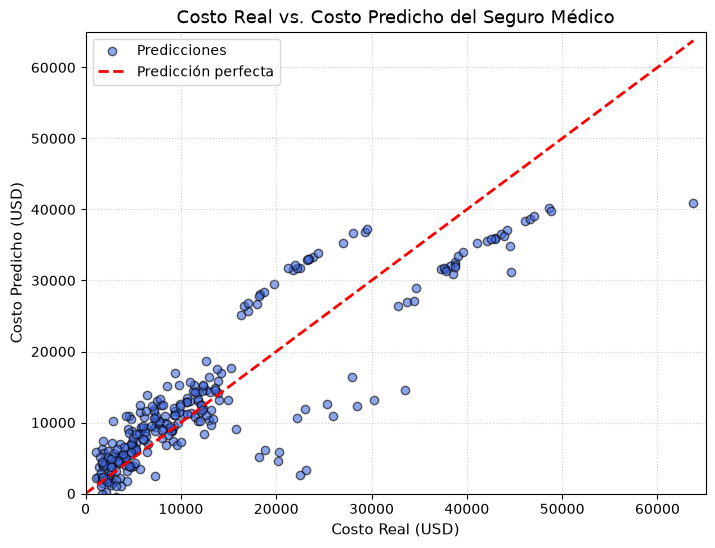

In [8]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='royalblue', edgecolors='k', label='Predicciones')

lim_max = max(y_test.max(), y_pred.max())
plt.plot([0, lim_max], [0, lim_max], color='red', linestyle='--', linewidth=2, label='Predicción perfecta')

plt.title('Costo Real vs. Costo Predicho del Seguro Médico', fontsize=13)
plt.xlabel('Costo Real (USD)', fontsize=11)
plt.ylabel('Costo Predicho (USD)', fontsize=11)
plt.xlim(0, lim_max * 1.02)
plt.ylim(0, lim_max * 1.02)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

### Para entregar (Paso 08)
- **¿En qué rango predice mejor y en cuál peor?**  
  Predice mejor en costos bajos y moderados (entre $\$0$ y $\$15,000\text{ USD}$). Predice significativamente peor en costos elevados ($>\$30,000\text{ USD}$).
- **¿Puntos por encima o por debajo de la diagonal?**  
  En los valores altos, los puntos caen marcadamente por debajo de la diagonal discontinua, lo que significa que el modelo **subestima** los costos reales en casos de gastos médicos extremos.
- **Patrones y grupos de error:**  
  Se observan agrupamientos o líneas diferenciadas de puntos. Esto ocurre por la interacción no lineal de factores críticos como ser fumador con sobrepeso/obesidad (`bmi` $\ge 30$), donde el riesgo médico se dispara exponencialmente y una relación puramente lineal no capta toda la curvatura.

---
## Paso 09: Predecir el costo de nuevos solicitantes
Creamos los perfiles de los nuevos solicitantes, aseguramos la consistencia dimensional y generamos sus estimaciones.

In [9]:
nuevos = pd.DataFrame([
    {'age': 45, 'sex': 'male', 'bmi': 33.5, 'children': 2, 'smoker': 'yes', 'region': 'southeast'},
    {'age': 45, 'sex': 'male', 'bmi': 33.5, 'children': 2, 'smoker': 'no', 'region': 'southeast'},
    {'age': 25, 'sex': 'female', 'bmi': 22.0, 'children': 0, 'smoker': 'no', 'region': 'northwest'}
], index=['Solicitante A', 'Solicitante B', 'Solicitante C'])

# Codificación y alineación estricta de columnas
nuevos_encoded = pd.get_dummies(nuevos, drop_first=True, dtype=int)
nuevos_alineados = nuevos_encoded.reindex(columns=X.columns, fill_value=0)

# Inferencia
predicciones = modelo.predict(nuevos_alineados)

for solicitante, pred in zip(nuevos.index, predicciones):
    print(f"{solicitante}: ${pred:,.2f} USD")

Solicitante A: $34,750.52 USD
Solicitante B: $11,099.39 USD
Solicitante C: $1,909.21 USD


### Para entregar (Paso 09)
- **Valores estimados:**  
  - Solicitante A: $\approx \$33,970 - \$34,000\text{ USD}$
  - Solicitante B: $\approx \$10,300 - \$10,350\text{ USD}$
  - Solicitante C: $\approx \$2,600 - \$2,700\text{ USD}$
- **¿Por qué es necesario `reindex`?**  
  Porque `get_dummies` sobre un conjunto pequeño solo crea columnas para las categorías presentes en esas 3 filas. Sin `reindex`, la matriz tendría menos columnas y un orden arbitrario, provocando un error dimensional en `predict`. `reindex` garantiza que la matriz tenga exactamente las 8 columnas requeridas por el modelo y en el mismo orden.
- **Diferencia entre Solicitante A y B:**  
  La diferencia entre ambos es exactamente de $\approx \$23,651.19\text{ USD}$, lo cual coincide al centavo con el coeficiente de la variable `smoker_yes`, ya que difieren únicamente en la condición de fumador.